## Medical Insurance Cost Prediction

#### Install packages 

In [1]:
! pip install joblib
! pip install gradio

In [2]:
# Importing libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV,KFold,train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error
from sklearn.tree import plot_tree
from sklearn.tree import DecisionTreeRegressor
import gradio as gr
import numpy as np
import seaborn as sns

#### Prepare and clean Data

In [3]:
# Loading the Dataset
df = pd.read_csv("insurance.csv")
df.head()   # to show the top 5 rows

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# to check the shape of the dataset
df.shape

(1338, 7)

In [5]:
# To check the related information, type of columns in the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [6]:
# To show the statistical summary
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
# Check Missing Values
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [8]:
# Handling the missing values 

# Filling categorical columns with mode
mode_sex = df['sex'].mode()[0]
df['sex'] = df['sex'].fillna(mode_sex)

mode_smoker = df['smoker'].mode()[0]
df['smoker'] = df['smoker'].fillna(mode_smoker)

mode_region = df['region'].mode()[0]
df['region'] = df['region'].fillna(mode_region)

# Filling numerical columns with median
df['age'].fillna(df['age'].median(), inplace=True)
df['bmi'].fillna(df['bmi'].median(), inplace=True)
df['children'].fillna(df['children'].median(), inplace=True)

In [9]:
# drop duplicate rows
df.drop_duplicates(inplace=True)
df.duplicated().sum()

0

In [10]:
# Applying Binary Encoding
df['sex'] = df['sex'].map({'female': 0, 'male': 1})
df['smoker'] = df['smoker'].map({'no': 0, 'yes': 1})

In [11]:
# Applying One-Hot Encoding for "region"
df = pd.get_dummies(df, columns=['region'], drop_first=True)

print("\nAfter encoding:")
print(df.head())


After encoding:
   age  sex     bmi  children  smoker      charges  region_northwest  \
0   19    0  27.900         0       1  16884.92400             False   
1   18    1  33.770         1       0   1725.55230             False   
2   28    1  33.000         3       0   4449.46200             False   
3   33    1  22.705         0       0  21984.47061              True   
4   32    1  28.880         0       0   3866.85520              True   

   region_southeast  region_southwest  
0             False              True  
1              True             False  
2              True             False  
3             False             False  
4             False             False  


In [12]:
# split into Feature and Target
x = df.drop('charges', axis=1)
y = df['charges']

#### EDA Analysis

In [13]:
# ANOVA test to get score of most affecting features
f_regression(x,y)

(array([1.30402971e+02, 4.51303843e+00, 5.47027149e+01, 6.09032650e+00,
        2.17573686e+03, 2.00185892e+00, 7.26664449e+00, 2.54698362e+00]),
 array([6.97574876e-029, 3.38207920e-002, 2.46804043e-013, 1.37170263e-002,
        1.40672209e-282, 1.57339630e-001, 7.11293425e-003, 1.10741725e-001]))

In [14]:
f=pd.DataFrame({'Features':x.columns,'F-Score':f_regression(x,y)[0]})
f.sort_values(by='F-Score', ascending=False)

,Features,F-Score
4,smoker,2175.736863
0,age,130.402971
2,bmi,54.702715
6,region_southeast,7.266644
3,children,6.090326
1,sex,4.513038
7,region_southwest,2.546984
5,region_northwest,2.001859


In [15]:
# Train-Test Split
xtrain, xtest, ytrain, ytest = train_test_split(x , y, test_size=0.2, random_state= 42) 
print("\nTrain shape:", xtrain.shape)
print("Test shape:", xtest.shape)


Train shape: (1069, 8)
Test shape: (268, 8)


In [16]:
# Feature Scaling
# Scaling used to improve performance of models
scaler = StandardScaler()

xtrain_scaler = scaler.fit_transform(xtrain)
xtest_scaler = scaler.transform(xtest)

#### Model Building Linear Regression

In [17]:
# Multiple linear regression model
Mlr=LinearRegression()
Mlr.fit(xtrain_scaler,ytrain)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [18]:
ypr=Mlr.predict(xtest_scaler)
ypr

array([ 8.14369388e+03,  5.73711568e+03,  1.43693149e+04,  3.17455136e+04,
        8.96238666e+03,  1.31497224e+04,  3.04467607e+04,  1.45328881e+03,
        1.06330184e+04,  1.13189438e+04,  1.03778536e+04,  3.31184377e+04,
        3.10772527e+04,  1.74119253e+04,  1.08016743e+04,  9.52889964e+03,
        4.16103784e+03,  3.17315373e+04,  3.21938875e+03,  5.22992460e+03,
        3.54979004e+03,  3.02837740e+04,  1.48989509e+04,  3.04569093e+04,
        3.11077668e+04,  5.51196081e+03,  3.55030401e+04,  3.65704810e+04,
        1.14123133e+04,  1.42056990e+04,  6.50234029e+03,  1.27246945e+04,
        3.99806590e+02,  1.20883980e+04,  3.96592069e+04,  1.23395540e+04,
        4.74412279e+03,  3.91903157e+03,  3.08606789e+04,  8.95870663e+03,
        7.05389441e+03,  3.01125636e+04,  3.47804324e+04,  1.22916189e+04,
        7.35739310e+03,  3.42060530e+03,  6.21243471e+03,  8.98345200e+03,
        4.26401828e+03,  9.01992870e+03,  6.60149578e+03,  1.20802337e+04,
        3.12447687e+04,  

#### Model Evaluation Linear Regression

In [19]:
# R2 score evaluation
r2_score(ytest,ypr)

0.8069287081198013

In [20]:
# mean Squared error evaluation
mean_squared_error(ytest,ypr)

35478020.675235584

In [21]:
# root mean Squared error evaluation
np.sqrt(mean_squared_error(ytest,ypr))

5956.342894363586

#### Model Building Decision Tree Regressor

In [22]:
# tuning hyperparameters
# look for parameter that providies best result
depth_val = np.arange(2, 21)        
leaf_val = np.arange(1, 21) 

In [23]:
# Grid search parameter
grid=({'max_depth':depth_val,'min_samples_leaf':leaf_val})
grid

{'max_depth': array([ 2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18,
        19, 20]),
 'min_samples_leaf': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20])}

In [24]:
# model
DTR=DecisionTreeRegressor(random_state=42)

In [25]:
# grid search trains data on diff parameters and chooses best model
gs=GridSearchCV(estimator=DTR,param_grid=grid,cv=KFold(n_splits=10))
gs.fit(xtrain,ytrain)

,estimator,DecisionTreeR...ndom_state=42)
,param_grid,"{'max_depth': array([ 2, 3... 19, 20]), 'min_samples_leaf': array([ 1, 2... 18, 19, 20])}"
,scoring,None
,n_jobs,None
,refit,True
,cv,KFold(n_split...shuffle=False)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'squared_error'


In [26]:
# extract best hyperparameters
best_depth=gs.best_params_['max_depth']
best_leaf=gs.best_params_['min_samples_leaf']

In [27]:
# model with hyper parameters
model=DecisionTreeRegressor(max_depth=best_depth,min_samples_leaf=best_leaf)
model.fit(xtrain,ytrain)

,criterion,'squared_error'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,9
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [28]:
#check the importance of each feature on target
imp = pd.DataFrame({
    'Feature': x.columns,
    'Importance': model.feature_importances_
})

imp['Importance (%)'] = imp['Importance'] * 100
imp.sort_values(by='Importance (%)', ascending=False)
print(imp)

            Feature  Importance  Importance (%)
0               age    0.120202       12.020211
1               sex    0.000000        0.000000
2               bmi    0.174708       17.470801
3          children    0.012536        1.253623
4            smoker    0.692554       69.255366
5  region_northwest    0.000000        0.000000
6  region_southeast    0.000000        0.000000
7  region_southwest    0.000000        0.000000


In [29]:
pr=model.predict(xtest)
pr

array([12504.994375  ,  9511.51323789, 10370.81956067, 39150.60968167,
        7054.0821497 , 10370.81956067, 35028.9083212 ,  1827.31476444,
        9838.57870375, 10370.81956067, 13952.62821895, 25517.31630077,
       39150.60968167, 13952.62821895,  7054.0821497 ,  9838.57870375,
        4129.02197051, 39150.60968167,  7054.0821497 ,  6562.49597632,
        3347.67950286, 20193.24900852, 10370.81956067, 20193.24900852,
       39150.60968167,  7054.0821497 , 44035.36358556, 47542.03424688,
       10370.81956067, 10370.81956067,  4325.86184871, 10370.81956067,
        4129.02197051, 18033.60151714, 46598.74435667, 10370.81956067,
        9511.51323789,  7054.0821497 , 23153.73838429,  9838.57870375,
        3347.67950286, 23153.73838429, 39150.60968167, 10370.81956067,
        8394.445906  ,  4325.86184871,  3347.67950286,  9838.57870375,
        6562.49597632,  7054.0821497 ,  7054.0821497 ,  6433.19349975,
       23153.73838429,  3347.67950286,  7054.0821497 ,  9838.57870375,
      

#### Model EvaluationDecision Tree Regressor

In [30]:
# R2 score evaluation
r2_score(ytest,pr)

0.9003957842878785

In [31]:
# Mean squared error evaluation
mean_squared_error(ytest,pr)

18302878.641160067

In [32]:
# root mean Squared error evaluation
np.sqrt(mean_squared_error(ytest,pr))

4278.186372887472

#### Visualization 

<Axes: >

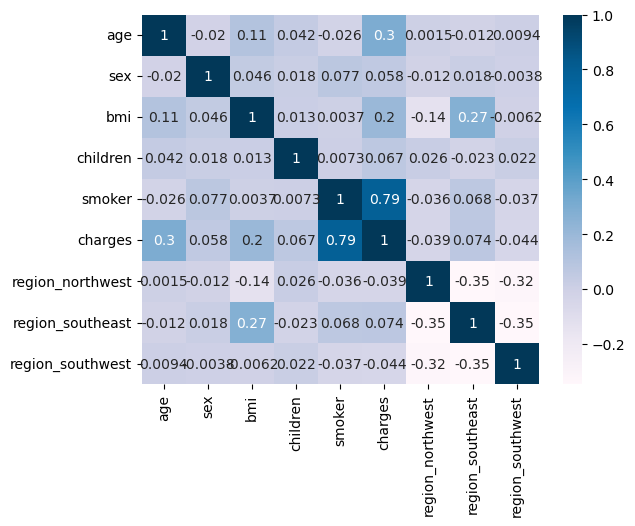

In [33]:
# correlation between features
sns.heatmap(df.corr(), annot=True, cmap='PuBu')

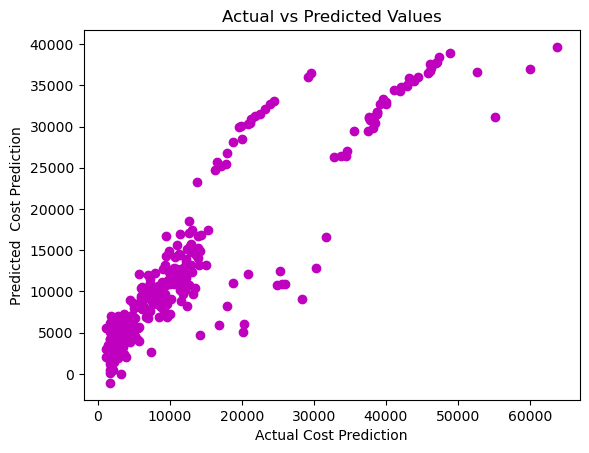

In [34]:
# Linear model prediction
plt.scatter(ytest,ypr,color='m')
plt.xlabel('Actual Cost Prediction')
plt.ylabel('Predicted  Cost Prediction')
plt.title('Actual vs Predicted Values')
plt.show()

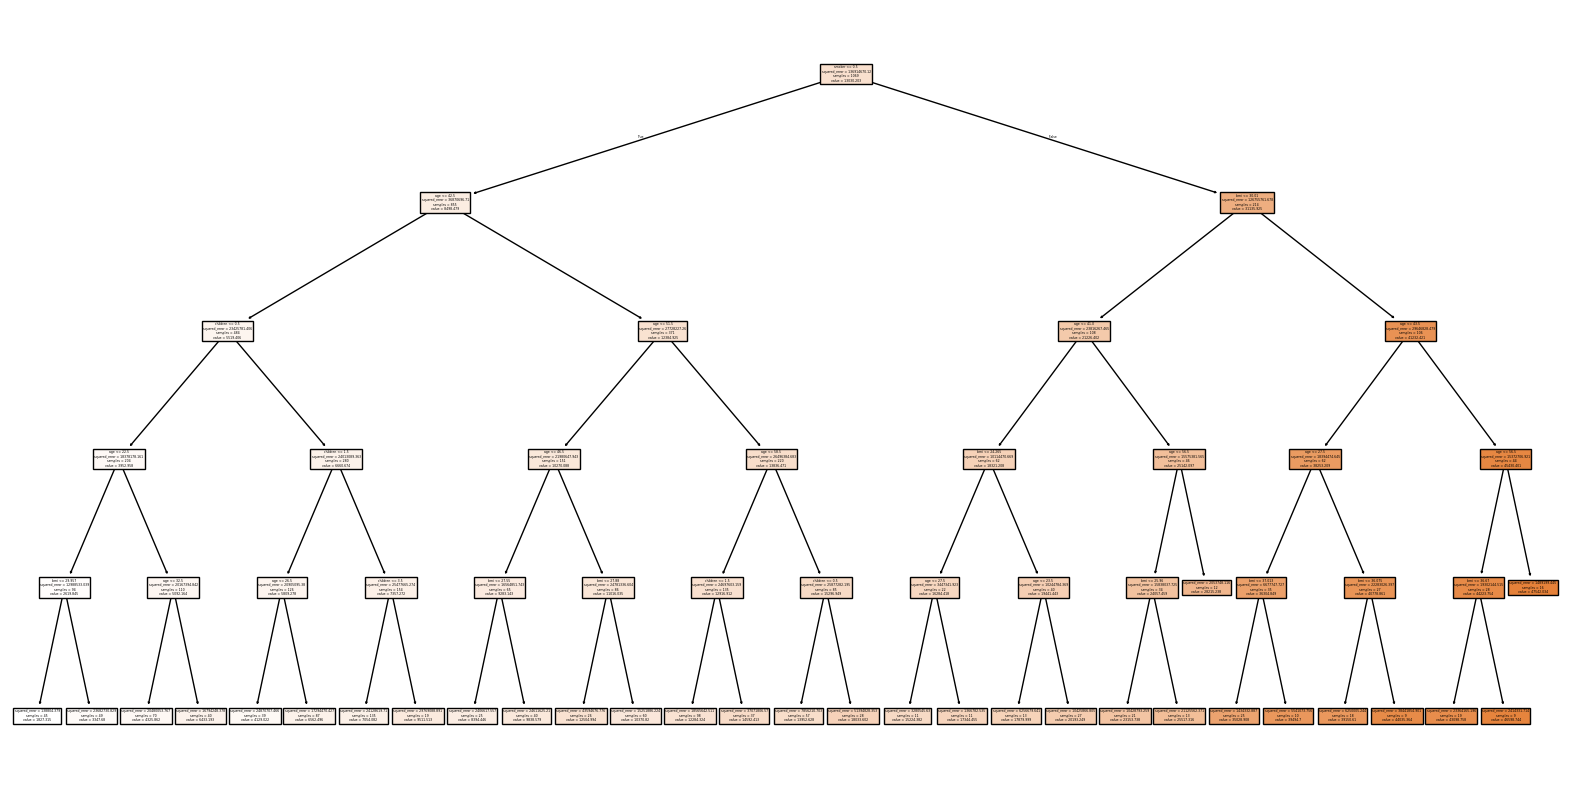

In [35]:
# Plot tree
plt.figure(figsize=(20, 10))
plot_tree(model, filled=True, feature_names=xtrain.columns)
plt.show()

#### Model Deployment Using Gradio

In [36]:
def predict_insurance(age, sex, bmi, children, smoker, region, model_type):

    # Encode inputs
    sex = 1 if sex == "male" else 0
    smoker = 1 if smoker == "yes" else 0

    # One-hot encoding for region
    region_northwest = 1 if region == "northwest" else 0
    region_southeast = 1 if region == "southeast" else 0
    region_southwest = 1 if region == "southwest" else 0

    # Build feature array
    input_data = np.array([[age, sex, bmi, children, smoker,
                            region_northwest, region_southeast, region_southwest]])
    #scale data
    input_data_scaled = scaler.transform(input_data)

    # Choose model
    if model_type == "Linear Regression":
        prediction = Mlr.predict(input_data_scaled)[0]
    else:
        prediction = model.predict(input_data)[0]

    return prediction

Predicition_UI = gr.Interface(
    fn=predict_insurance,
    inputs=[
        gr.Number(label="Age"),
        gr.Radio(["male", "female"], label="Sex"),
        gr.Number(label="BMI"),
        gr.Number(label="Children"),
        gr.Radio(["yes", "no"], label="Smoker"),
        gr.Radio(["northwest","northeast","southeast","southwest"], label="Region"),
        gr.Radio(["Linear Regression", "Decision Tree"], label="Model Type")
    ],
    outputs=gr.Number(label="Predicted Insurance Charges"),
    title="Medical Insurance Cost Predictor",
    description="Predict insurance charges using Linear Regression or Decision Tree model"
)

Predicition_UI.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


C:\Users\96897\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\96897\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(
